In [16]:
import pandas as pd
import numpy as np
import torch
import timesfm
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tqdm import tqdm
print("Import thư viện thành công!")

Import thư viện thành công!


In [17]:
print("Đang load mô hình TimesFM 2.5...")

torch.set_float32_matmul_precision("high")

model = timesfm.TimesFM_2p5_200M_torch.from_pretrained(
    "google/timesfm-2.5-200m-pytorch",
    torch_compile=True
)

model.compile(
    timesfm.ForecastConfig(
        max_context=8192,
        max_horizon=1,
        normalize_inputs=True,
        use_continuous_quantile_head=True,
        force_flip_invariance=True
    )
)

print("Load mô hình TimesFM 2.5 thành công!")

Đang load mô hình TimesFM 2.5...
Load mô hình TimesFM 2.5 thành công!


In [18]:
df = pd.read_csv('merged_data_final.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['id', 'timestamp']).reset_index(drop=True)

print("Đã load dữ liệu thành công!")
print("Shape:", df.shape)
print("Các mã cổ phiếu:", sorted(df['id'].unique()))

Đã load dữ liệu thành công!
Shape: (12344, 19)
Các mã cổ phiếu: ['FPT', 'HPG', 'SSI', 'VCB', 'VHM', 'VNM']


In [19]:
unique_ids = df['id'].unique()
print("Tổng số mã cổ phiếu cần backtest:", len(unique_ids))

Tổng số mã cổ phiếu cần backtest: 6


In [20]:
def rolling_one_step_backtest_30days(stock_df):
    """
    Backtest chỉ trên 30 ngày cuối cùng
    """
    n = len(stock_df)
    if n < 100:  # cần đủ dữ liệu để làm context
        return None
    
    test_days = 30
    split_index = n - test_days   # 30 ngày cuối là phần test
    
    # Context ban đầu
    context_prices = stock_df['Close'].iloc[:split_index].values.astype(np.float32).copy()
    
    actual = []
    predicted = []
    dates = []
    
    for i in range(split_index, n):
        point_forecast, _ = model.forecast(horizon=1, inputs=[context_prices])
        
        actual.append(stock_df['Close'].iloc[i])
        predicted.append(point_forecast[0][0])
        dates.append(stock_df['timestamp'].iloc[i])
        
        # Rolling: thêm giá thực tế vào context
        context_prices = np.append(context_prices, stock_df['Close'].iloc[i])
    
    return {
        'actual': np.array(actual),
        'predicted': np.array(predicted),
        'dates': dates,
        'days_test': test_days
    }

In [21]:
print("Bắt đầu chạy Rolling One-Step Backtest (30 ngày cuối)...")

backtest_results = {}   # lưu chi tiết để vẽ biểu đồ
summary_results = []

unique_ids = df['id'].unique()

for stock_id in tqdm(unique_ids, desc="Đang backtest từng mã"):
    stock_df = df[df['id'] == stock_id].copy()
    
    result = rolling_one_step_backtest_30days(stock_df)
    if result is None:
        continue
    
    # Lưu chi tiết
    backtest_results[stock_id] = result
    
    # Tính chỉ số
    mae = mean_absolute_error(result['actual'], result['predicted'])
    rmse = np.sqrt(mean_squared_error(result['actual'], result['predicted']))
    mape = np.mean(np.abs((result['actual'] - result['predicted']) / result['actual'])) * 100
    
    summary_results.append({
        'id': stock_id,
        'days_test': result['days_test'],
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE': round(mape, 2)
    })

print("Backtest hoàn tất!")

Bắt đầu chạy Rolling One-Step Backtest (30 ngày cuối)...


Đang backtest từng mã: 100%|██████████| 6/6 [02:01<00:00, 20.18s/it]

Backtest hoàn tất!


In [22]:
summary_df = pd.DataFrame(summary_results)
print("=== KẾT QUẢ ROLLING ONE-STEP BACKTEST (30 NGÀY CUỐI) ===")
print(summary_df.sort_values(by='MAPE').round(2))

summary_df.to_csv('backtest_30days_summary.csv', index=False)
print("\nĐã lưu kết quả vào file: backtest_30days_summary.csv")

=== KẾT QUẢ ROLLING ONE-STEP BACKTEST (30 NGÀY CUỐI) ===
    id  days_test   MAE  RMSE  MAPE
3  VCB         30  0.28  0.39  0.48
0  FPT         30  0.89  1.14  0.93
1  HPG         30  0.27  0.30  1.00
5  VNM         30  0.91  1.17  1.45
2  SSI         30  0.52  0.66  1.74
4  VHM         30  3.07  4.17  2.82

Đã lưu kết quả vào file: backtest_30days_summary.csv


In [23]:
top6_ids = summary_df.nsmallest(6, 'MAPE')['id'].tolist()
print("6 mã có MAPE tốt nhất sẽ được vẽ biểu đồ:")
print(top6_ids)

6 mã có MAPE tốt nhất sẽ được vẽ biểu đồ:
['VCB', 'FPT', 'HPG', 'VNM', 'SSI', 'VHM']


In [29]:
import matplotlib.dates as mdates

def plot_top_stock(idx, window=60):
    if idx >= len(top6_ids):
        print(f"Không có top6_ids[{idx}]")
        return

    stock_id = top6_ids[idx]
    result = backtest_results[stock_id]
    stock_df = df[df["id"] == stock_id].copy()

    window = min(window, len(stock_df))
    zoom_df = stock_df.iloc[-window:].copy()

    pred_df = pd.DataFrame({
        "timestamp": pd.to_datetime(result["dates"]),
        "predicted": result["predicted"],
        "actual_test": result["actual"]
    }).sort_values("timestamp")

    pred_zoom = pred_df[pred_df["timestamp"] >= zoom_df["timestamp"].min()].copy()
    test_start_date = stock_df["timestamp"].iloc[-30]

    if len(pred_zoom) > 0:
        mae = mean_absolute_error(pred_zoom["actual_test"], pred_zoom["predicted"])
        rmse = np.sqrt(mean_squared_error(pred_zoom["actual_test"], pred_zoom["predicted"]))
        denom = pred_zoom["actual_test"].replace(0, np.nan)
        mape = np.nanmean(np.abs((pred_zoom["actual_test"] - pred_zoom["predicted"]) / denom)) * 100
    else:
        mae = rmse = mape = np.nan

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(zoom_df["timestamp"], zoom_df["Close"], color="#1f77b4", linewidth=2.4, label="Giá thực tế (60 ngày cuối)")

    if len(pred_zoom) > 0:
        ax.plot(pred_zoom["timestamp"], pred_zoom["predicted"], color="#d62728", linestyle="--",
                linewidth=2.2, marker="o", markersize=3, label="Giá dự báo")
        ax.fill_between(pred_zoom["timestamp"], pred_zoom["actual_test"], pred_zoom["predicted"],
                        color="#ff9896", alpha=0.25, label="Sai số")

    ax.axvline(test_start_date, color="gray", linestyle="--", linewidth=1.5, label="Bắt đầu 30 ngày test")
    ax.axvspan(test_start_date, zoom_df["timestamp"].max(), color="gray", alpha=0.08)

    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
    plt.xticks(rotation=45)

    ax.set_title(f"Rolling One-Step Backtest (Zoom {window} ngày cuối) - Mã {stock_id}", fontsize=13, weight="bold")
    ax.set_xlabel("Ngày")
    ax.set_ylabel("Giá")
    ax.grid(True, alpha=0.25, linestyle="--")
    ax.legend(loc="best")

    if len(pred_zoom) > 0:
        ax.text(0.02, 0.95, f"MAE: {mae:.2f} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%",
                transform=ax.transAxes, va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9))

    plt.tight_layout()
    plt.show()

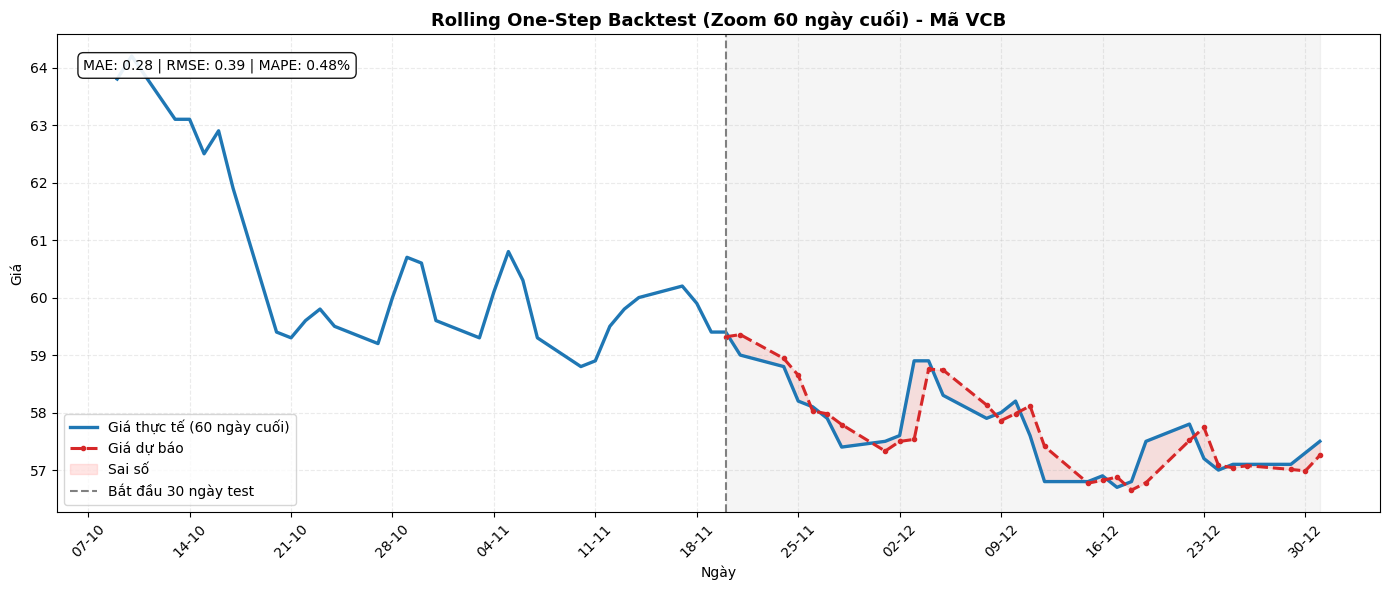

In [30]:
plot_top_stock(0)

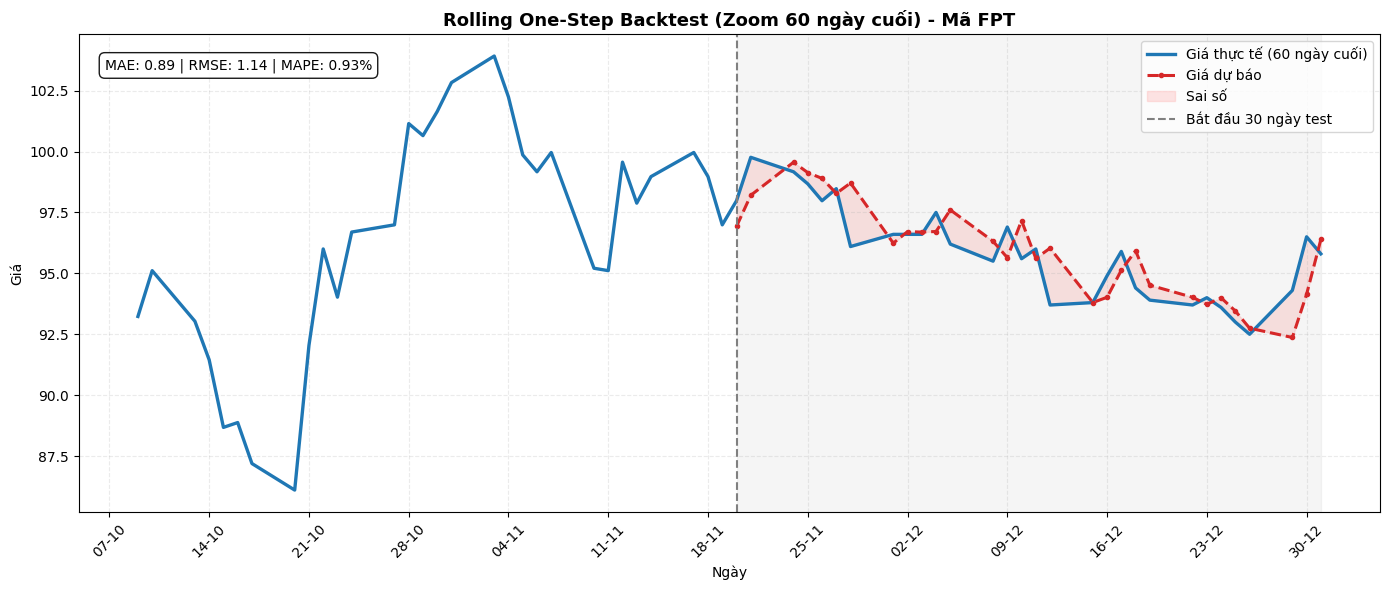

In [31]:
plot_top_stock(1)

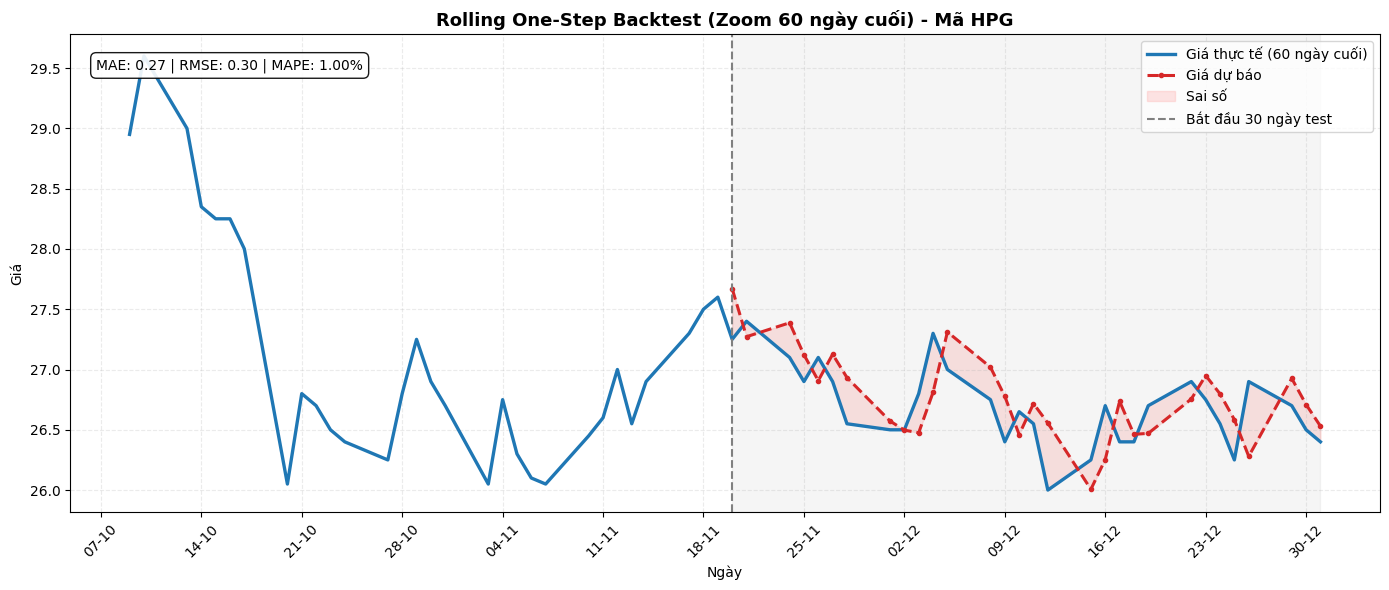

In [32]:
plot_top_stock(2)

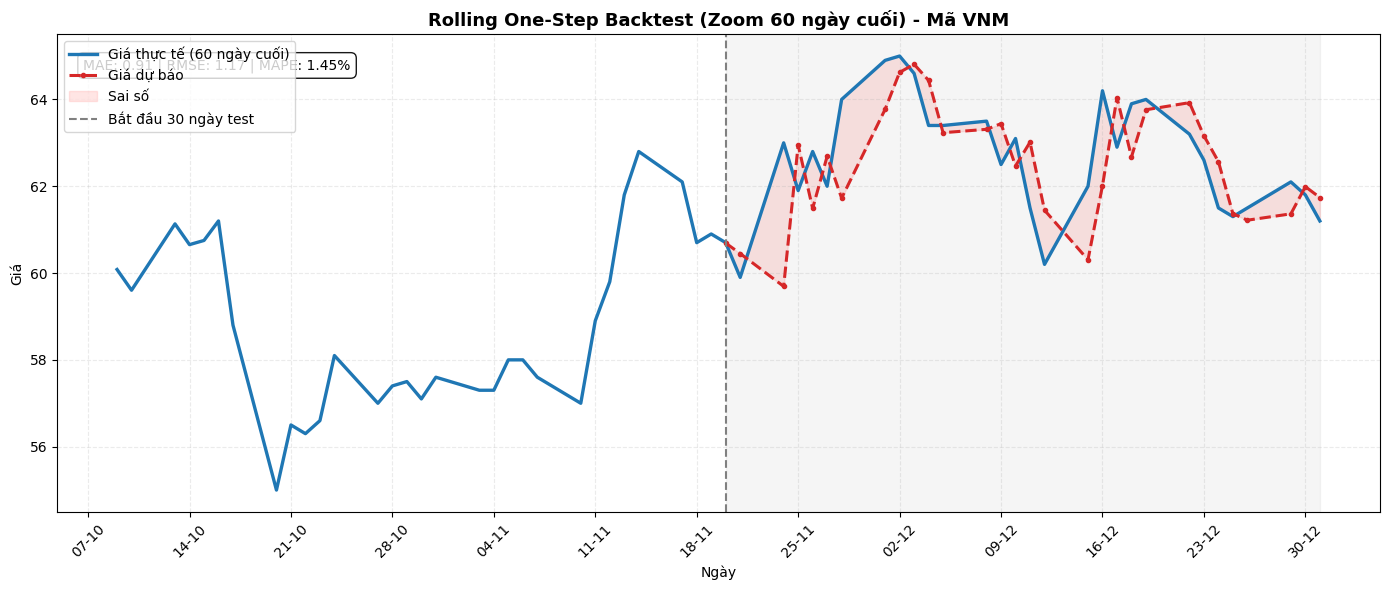

In [33]:
plot_top_stock(3)

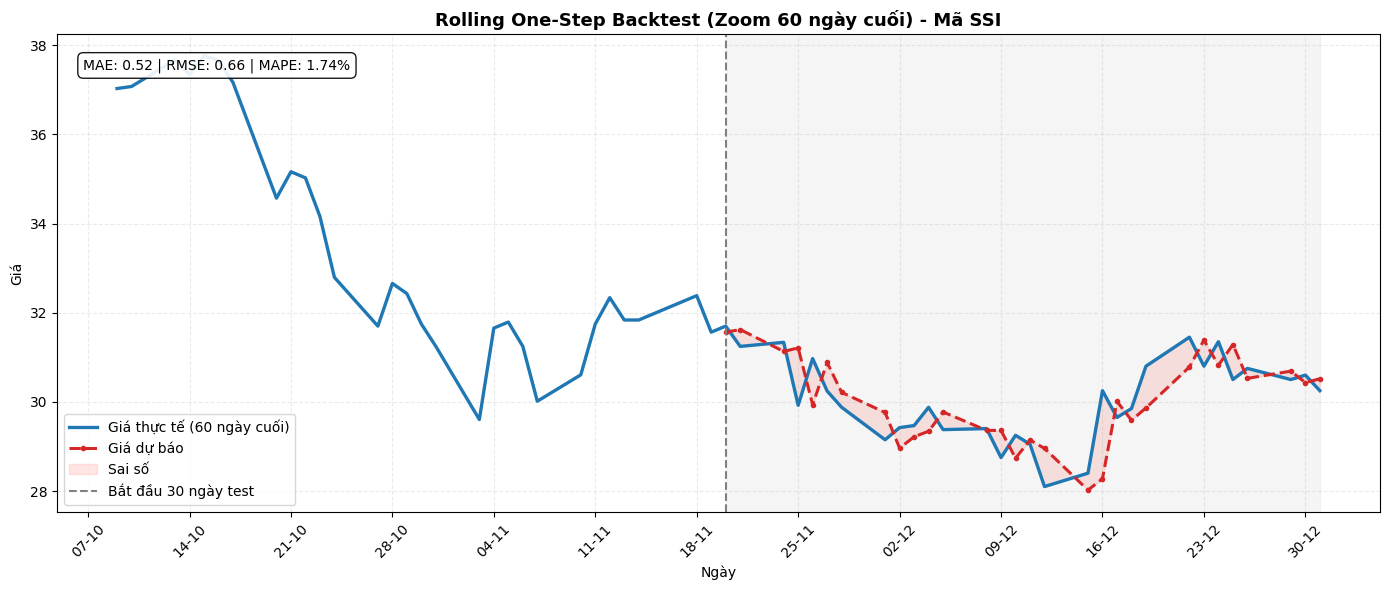

In [34]:
plot_top_stock(4)

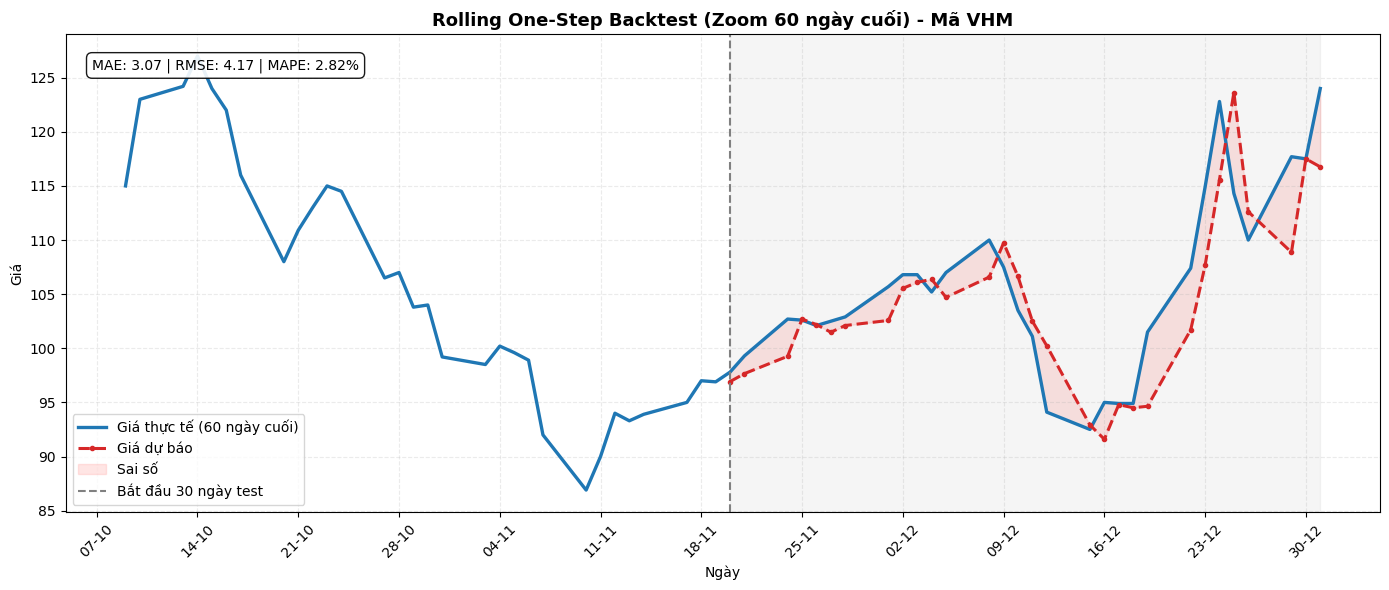

In [35]:
plot_top_stock(5)